In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from keras import models,layers
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 105.3 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.0
    Uninstalling scikit-learn-1.2.0:
      Successfully uninstalled scikit-learn-1.2.0


In [ ]:
#Load the data
cifar10data=keras.datasets.cifar10

(X_train_full, y_train_full),(X_test,y_test)=cifar10data.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
#Normalization
train_images, test_images=X_train_full/255.0, X_test/255.0

In [ ]:
#Classes names
class_names=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
#10 classes de predictions (multi_classes prediction ou encore du multi_label prediction)


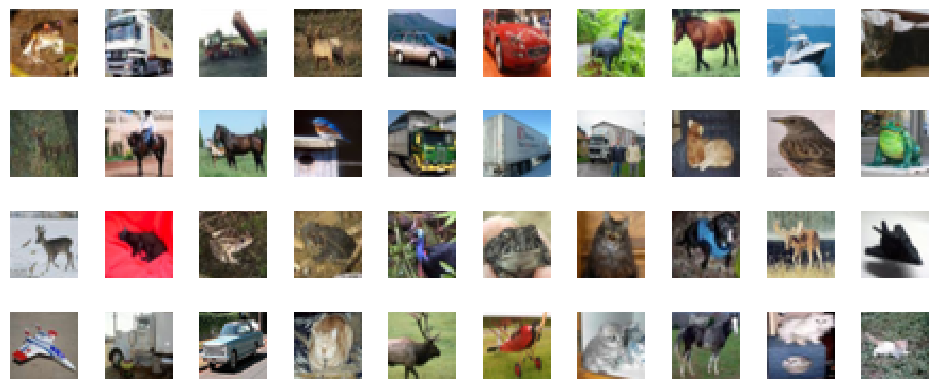

In [ ]:
n_rows=4
n_cols=10
plt.figure(figsize=(n_cols*1.2,n_rows*1.2))
for row in range(n_rows):
  for col in range(n_cols):
    index=n_cols*row+col
    plt.subplot(n_rows,n_cols,index+1)
    plt.imshow(train_images[index],cmap="binary",interpolation="nearest")
    plt.axis("off")
plt.subplots_adjust(wspace=0.2,hspace=0.5)
plt.show()

In [ ]:
train_images.shape
# input : (50000, 32, 32, 3) et en output (None, 10 classes )

(50000, 32, 32, 3)

In [ ]:
#Construct convolutional neural Network

model=models.Sequential()
model.add(layers.Conv2D(32,(3,3),activation="relu",input_shape=(32,32,3)))#Appliquer un filtre , par defaut il applique un filtre de 3*3 ===> 30*30 sans padding || avec padding on peut se retrouver avec du 32*32
#Output 1=30*30
model.add(layers.MaxPooling2D((2,2)))
#Output 2=15*15
model.add(layers.Conv2D(64,(3,3),activation="relu"))
#Output 3=13*13
model.add(layers.MaxPooling2D((2,2)))
#Output 4=6*6
model.add(layers.Conv2D(64,(3,3),activation="relu"))
#Output 5=4*4
model.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Adding dense laye
model.add(layers.Flatten())
#Output (None,16,64)
model.add(layers.Dense(64,activation="relu"))
model.add(layers.Dense(10))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compilation du model et entrainement
model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])


In [ ]:
y_test

array([[3],
       [8],
       [8],
       ...,
       [5],
       [1],
       [7]], dtype=uint8)

In [ ]:
#L'entrainement
history=model.fit(train_images,
                  y_train_full,
                  epochs=50,validation_data=(test_images,y_test),callbacks=[keras.callbacks.EarlyStopping(patience=5)])

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 49ms/step - accuracy: 0.3890 - loss: 1.6632 - val_accuracy: 0.5064 - val_loss: 1.3649
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 67s 43ms/step - accuracy: 0.5606 - loss: 1.2201 - val_accuracy: 0.6135 - val_loss: 1.0844
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 42ms/step - accuracy: 0.6376 - loss: 1.0393 - val_accuracy: 0.6434 - val_loss: 1.0180
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 42ms/step - accuracy: 0.6760 - loss: 0.9223 - val_accuracy: 0.6562 - val_loss: 0.9696
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 41ms/step - accuracy: 0.7024 - loss: 0.8454 - val_accuracy: 0.6687 - val_loss: 0.9511
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 41ms/step - accuracy: 0.7228 - loss: 0.7831 - val_accuracy: 0.6994 - val_loss: 0.8726
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 41ms/step - accuracy: 0.7440 - loss: 0.7305 - val_accuracy: 0.6884 - val_loss: 0.9128
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 41ms/step - accuracy: 0.7625 -

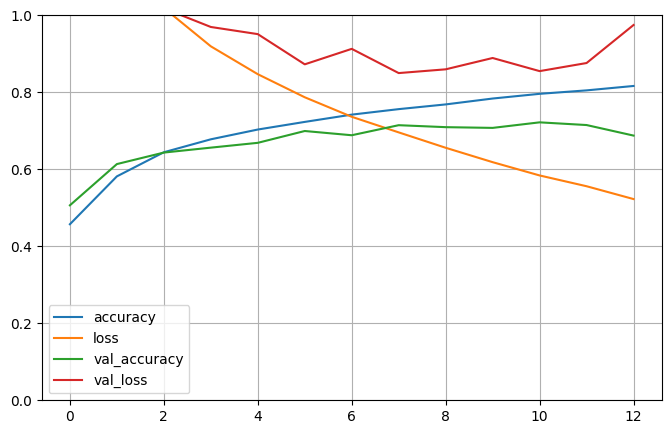

In [ ]:
#Print historical data
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [ ]:
# Model evaluation
model.evaluate(test_images,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6909 - loss: 0.9705


[0.9747307896614075, 0.6875]

In [ ]:
#Class prediction
X_new=test_images[:5]
y_proba=model.predict(X_new)
y_proba.round(2) #arrondir les probabilités

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step


array([[ -2.26,  -3.45,  -2.51,   3.14,  -1.72,   1.32,   1.24,  -1.57,
         -0.62,  -3.27],
       [  6.32,  14.14, -10.02,  -6.71,  -9.94, -10.3 ,  -3.2 , -10.43,
         11.21,   8.37],
       [  1.2 ,   0.47,  -1.49,  -0.73,  -2.3 ,  -1.64,  -0.3 ,  -1.18,
          3.47,  -0.61],
       [  4.26,   1.25,   2.43,   0.69,  -1.48,  -2.91,   2.45,  -7.45,
          0.71,  -0.16],
       [ -7.04,  -2.22,   2.91,   1.53,   9.75,  -1.59,   7.44,  -7.87,
         -7.05,  -1.98]], dtype=float32)

In [ ]:
y_pred=np.argmax(y_proba,axis=1)
y_pred


array([3, 1, 8, 0, 4])

In [ ]:
y_test[:5]

array([[3],
       [8],
       [8],
       [0],
       [6]], dtype=uint8)

In [ ]:
class_names=['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']


In [ ]:
!pip install scikeras

In [ ]:
from scikeras.wrappers import KerasClassifier, KerasRegressor
from sklearn.model_selection import GridSearchCV

In [ ]:
#Grid search
def build_model(optimizer='adam',filters=32,n_neurons=30):
  model=models.Sequential()
  model.add(layers.Conv2D(32,(3,3),activation="relu",input_shape=(32,32,3)))#Appliquer un filtre , par defaut il applique un filtre de 3*3 ===> 30*30 sans padding || avec padding on peut se retrouver avec du 32*32
  #Output 1=30*30
  model.add(layers.MaxPooling2D((2,2)))
  #Output 2=15*15
  model.add(layers.Conv2D(64,(3,3),activation="relu"))
  #Output 3=13*13
  model.add(layers.MaxPooling2D((2,2)))
  #Output 4=6*6
  model.add(layers.Conv2D(64,(3,3),activation="relu"))
  #Adding dense laye
  model.add(layers.Flatten())
  #Output (None,16,64)
  model.add(layers.Dense(64,activation="relu"))
  model.add(layers.Dense(10,activation='softmax'))

  model.compile(optimizer=optimizer,
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
  return model

#Fin de la definition de la fonction build_model

keras_model=KerasRegressor(build_fn=build_model,epochs=5,
                            batch_size=64,verbose=1)

#Parameter grid
param_grid={'optimizer':['adam', 'sdg'],
            'filters':[32,64],
            'dense_neurons': [64,128],
            'batch_size':[32,64]
            }

#Run grid search
grid=GridSearchCV(keras_model,param_grid=param_grid,cv=3,n_jobs=1,verbose=2)
#grid_result=grid.fit(X_train,y_train)
grid_results=grid.fit(train_images,y_train_full)

In [ ]:
y_train_full.shape

(50000, 1)